<div style="text-align: center; background: #ff8c00; font-family: 'Montserrat', sans-serif; color: white; padding: 15px; font-size: 30px; font-weight: bold; line-height: 1; border-radius: 20px 20px 0 0; margin-bottom: 20px; box-shadow: 0px 4px 6px rgba(0, 0, 0, 0.2);">🚀 Classification d'emails : 10 catégories 🚀</div>

<div style="text-align: center; background: #1ED760; font-family: 'Trebuchet MS', Arial, sans-serif; color: white; padding: 15px; font-size: 26px; font-weight: bold; line-height: 1; border-radius: 50% 0 50% 0 / 40px; margin-bottom: 20px; box-shadow: 0px 4px 6px rgba(0, 0, 0, 0.1);">1. Introduction</div>

<div style="text-align: center; background: #1ED760; font-family: 'Trebuchet MS', Arial, sans-serif; color: white; padding: 15px; font-size: 26px; font-weight: bold; line-height: 1; border-radius: 50% 0 50% 0 / 40px; margin-bottom: 20px; box-shadow: 0px 4px 6px rgba(0, 0, 0, 0.1);">2. Problem Statement</div>

« L'objectif principal de ce notebook est de développer un modèle prédictif capable de classifier avec précision les emails en fonction de leur label : <span style="background-color: #FF5733; color: white; font-weight: bold; padding: 3px 6px; border-radius: 3px;">games</span>, <span style="background-color: #FF5733; color: white; font-weight: bold; padding: 3px 6px; border-radius: 3px;">sport</span>, <span style="background-color: #FF5733; color: white; font-weight: bold; padding: 3px 6px; border-radius: 3px;">family</span>, <span style="background-color: #FF5733; color: white; font-weight: bold; padding: 3px 6px; border-radius: 3px;">work/airbus</span>, <span style="background-color: #FF5733; color: white; font-weight: bold; padding: 3px 6px; border-radius: 3px;">human resources</span>, <span style="background-color: #FF5733; color: white; font-weight: bold; padding: 3px 6px; border-radius: 3px;">pets</span>, <span style="background-color: #FF5733; color: white; font-weight: bold; padding: 3px 6px; border-radius: 3px;">school</span>, <span style="background-color: #FF5733; color: white; font-weight: bold; padding: 3px 6px; border-radius: 3px;">software engineering</span>, <span style="background-color: #FF5733; color: white; font-weight: bold; padding: 3px 6px; border-radius: 3px;">finance</span>. Nous utiliserons le jeu de données local, qui contient des objets et corps d'emails annotés avec leurs labels respectifs. »

<div style="text-align: center; background: #FF00CC; font-family: 'Trebuchet MS', Arial, sans-serif; color: white; padding: 15px; font-size: 26px; font-weight: bold; line-height: 1; border-radius: 50% 0 50% 0 / 40px; margin-bottom: 20px; box-shadow: 0px 4px 6px rgba(0, 0, 0, 0.1);">3.1 Import Necessary Libraries</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from wordcloud import WordCloud

import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/shepard/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /home/shepard/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/shepard/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [2]:
df = pd.read_csv('emails_dataset.csv', encoding='utf-8')

In [3]:
styled_df = df.head().style.set_table_styles([
    {"selector": "th", "props": [("color", 'black'), ("background-color", "#FF00CC")]}
])
styled_df

,subject,body,label
0,Job Posting for Marketing Coordinator,"Hello Sarah, we are looking to fill the open marketing coordinator position. Could you please review the attached job description and let me know if it needs any revisions?",human resources
1,Automated System: Benefits Enrollment Reminder,"Dear Employee, This is a friendly reminder to enroll in our benefits program. If you have not already done so, please log in to the intranet and complete the enrollment process before the deadline. Best regards, HR System",human resources
2,Job Interview with Alex,"Hi team, Alex will be here for his job interview on Friday at 2 PM. Could we please make sure to have a copy of his resume and any other relevant materials ready for him? Thanks, Emily",human resources
3,Employee Handbook Update,"Dear Employees, As per company policy, we will be updating our employee handbook to reflect the new dress code policy. Please review the changes and let us know if you have any questions or concerns. Best regards, HR Department",human resources
4,New Employee Onboarding Process,"Hello, I am reaching out to inquire about the onboarding process for our new employees. We have had some issues in the past with the current process and I was wondering if we could discuss possible improvements. Thank you for your time and consideration.",human resources


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9499 entries, 0 to 9498
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   subject  9499 non-null   object
 1   body     9499 non-null   object
 2   label    9499 non-null   object
dtypes: object(3)
memory usage: 222.8+ KB


<div style="text-align: center; background: #FF00CC; font-family: 'Trebuchet MS', Arial, sans-serif; color: white; padding: 15px; font-size: 26px; font-weight: bold; line-height: 1; border-radius: 50% 0 50% 0 / 40px; margin-bottom: 20px; box-shadow: 0px 4px 6px rgba(0, 0, 0, 0.1);">4. Data Preparation</div>

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>4.2 | Drop the Columns</b></span>

In [5]:
df = df[['subject', 'body', 'label']].copy()

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>4.3 | Construire la colonne texte</b></span>

In [6]:
df['text'] = (df['subject'].fillna('') + ' ' + df['body'].fillna('')).str.strip()

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>4.4 | Encoder les labels</b></span>

In [7]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
df['target'] = encoder.fit_transform(df['label'])
label_mapping = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))
print('Label mapping:', label_mapping)

Label mapping: {'family': np.int64(0), 'finance': np.int64(1), 'games': np.int64(2), 'human resources': np.int64(3), 'medical': np.int64(4), 'pets': np.int64(5), 'school': np.int64(6), 'software engineering': np.int64(7), 'sport': np.int64(8), 'work/airbus': np.int64(9)}


> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>4.5 | Check Missing values</b></span>

In [8]:
df.isnull().sum()

subject    0
body       0
label      0
text       0
target     0
dtype: int64

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>4.6 | Check & Remove Duplicates</b></span>

In [9]:
print('Duplicates:', df.duplicated().sum())
df = df.drop_duplicates(keep='first')
print('Shape after dedup:', df.shape)

Duplicates: 67
Shape after dedup: (9432, 5)


<div style="text-align: center; background: #FF00CC; font-family: 'Trebuchet MS', Arial, sans-serif; color: white; padding: 15px; font-size: 26px; font-weight: bold; line-height: 1; border-radius: 50% 0 50% 0 / 40px; margin-bottom: 20px; box-shadow: 0px 4px 6px rgba(0, 0, 0, 0.1);">5. EDA</div>

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>5.1 | Distribution des 10 catégories</b></span>

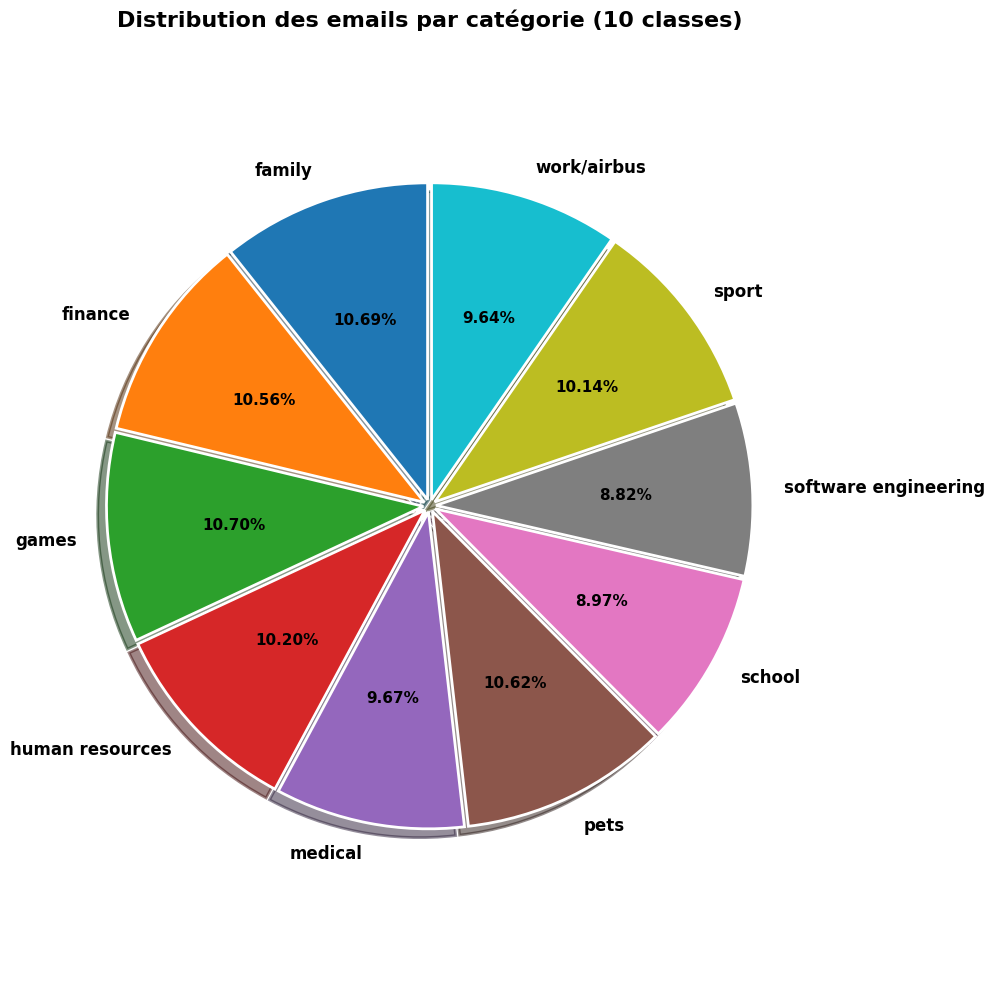

In [10]:
import matplotlib.cm as cm

values = df['label'].value_counts().sort_index()

# Palette dynamique adaptée à 10 classes
colors = [cm.tab10(i) for i in range(len(values))]
explode = [0.02] * len(values)

fig, ax = plt.subplots(figsize=(10, 10))
ax.set_facecolor('white')

wedges, texts, autotexts = ax.pie(
    values.values,
    labels=values.index.tolist(),
    autopct='%0.2f%%',
    startangle=90,
    colors=colors,
    wedgeprops={'linewidth': 2, 'edgecolor': 'white'},
    explode=explode,
    shadow=True
)

for text, autotext in zip(texts, autotexts):
    text.set(size=12, weight='bold')
    autotext.set(size=11, weight='bold')

ax.set_title('Distribution des emails par catégorie (10 classes)', fontsize=16, fontweight='bold')
ax.axis('equal')
plt.tight_layout()
plt.show()

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>5.2 | Comptage par catégorie</b></span>

/tmp/ipykernel_9177/1667933912.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', order=df['label'].value_counts().index, palette='tab10')


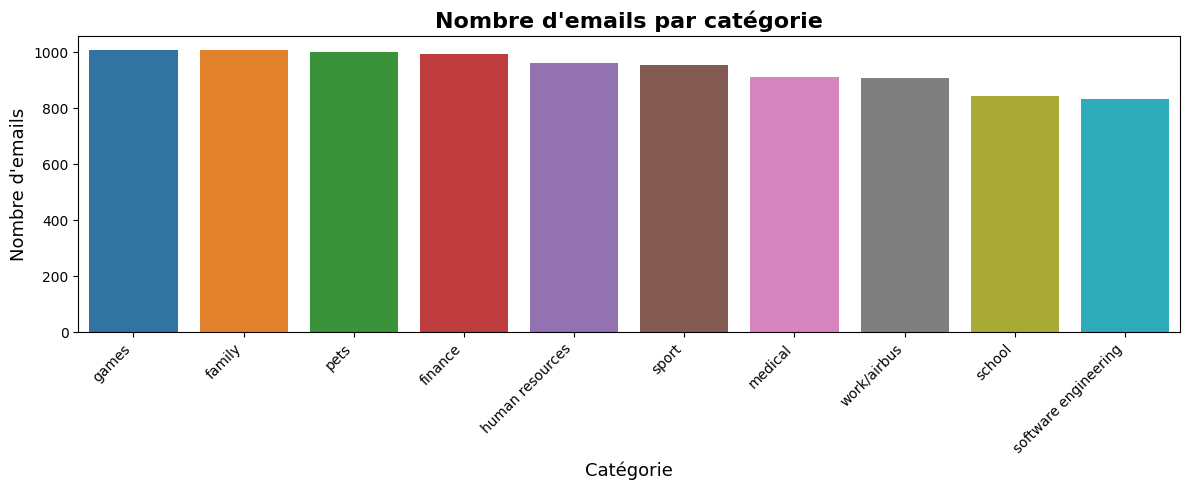

In [11]:
import seaborn as sns

plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='label', order=df['label'].value_counts().index, palette='tab10')
plt.title('Nombre d\'emails par catégorie', fontsize=16, fontweight='bold')
plt.xlabel('Catégorie', fontsize=13)
plt.ylabel('Nombre d\'emails', fontsize=13)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

<div style="text-align: center; background: #FF00CC; font-family: 'Trebuchet MS', Arial, sans-serif; color: white; padding: 15px; font-size: 26px; font-weight: bold; line-height: 1; border-radius: 50% 0 50% 0 / 40px; margin-bottom: 20px; box-shadow: 0px 4px 6px rgba(0, 0, 0, 0.1);">6. Data Preprocessing</div>

In [12]:
from nltk.stem.porter import PorterStemmer
import string

ps = PorterStemmer()

def transform_text(text):
    text = text.lower()
    text = nltk.word_tokenize(text)

    # Suppression des caractères spéciaux
    y = [i for i in text if i.isalnum()]

    # Suppression stopwords et ponctuation
    y = [i for i in y if i not in stopwords.words('english') and i not in string.punctuation]

    # Stemming
    y = [ps.stem(i) for i in y]

    return " ".join(y)

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>6.1 | Création de la colonne transformed_text</b></span>

In [13]:
df['transformed_text'] = df['text'].apply(transform_text)

df.head(5).style.set_table_styles([
    {"selector": "th", "props": [("color", 'Black'), ("background-color", "#FF00CC"), ('font-weight', 'bold')]}
])

,subject,body,label,text,target,transformed_text
0,Job Posting for Marketing Coordinator,"Hello Sarah, we are looking to fill the open marketing coordinator position. Could you please review the attached job description and let me know if it needs any revisions?",human resources,"Job Posting for Marketing Coordinator Hello Sarah, we are looking to fill the open marketing coordinator position. Could you please review the attached job description and let me know if it needs any revisions?",3,job post market coordin hello sarah look fill open market coordin posit could pleas review attach job descript let know need revis
1,Automated System: Benefits Enrollment Reminder,"Dear Employee, This is a friendly reminder to enroll in our benefits program. If you have not already done so, please log in to the intranet and complete the enrollment process before the deadline. Best regards, HR System",human resources,"Automated System: Benefits Enrollment Reminder Dear Employee, This is a friendly reminder to enroll in our benefits program. If you have not already done so, please log in to the intranet and complete the enrollment process before the deadline. Best regards, HR System",3,autom system benefit enrol remind dear employe friendli remind enrol benefit program alreadi done pleas log intranet complet enrol process deadlin best regard hr system
2,Job Interview with Alex,"Hi team, Alex will be here for his job interview on Friday at 2 PM. Could we please make sure to have a copy of his resume and any other relevant materials ready for him? Thanks, Emily",human resources,"Job Interview with Alex Hi team, Alex will be here for his job interview on Friday at 2 PM. Could we please make sure to have a copy of his resume and any other relevant materials ready for him? Thanks, Emily",3,job interview alex hi team alex job interview friday 2 pm could pleas make sure copi resum relev materi readi thank emili
3,Employee Handbook Update,"Dear Employees, As per company policy, we will be updating our employee handbook to reflect the new dress code policy. Please review the changes and let us know if you have any questions or concerns. Best regards, HR Department",human resources,"Employee Handbook Update Dear Employees, As per company policy, we will be updating our employee handbook to reflect the new dress code policy. Please review the changes and let us know if you have any questions or concerns. Best regards, HR Department",3,employe handbook updat dear employe per compani polici updat employe handbook reflect new dress code polici pleas review chang let us know question concern best regard hr depart
4,New Employee Onboarding Process,"Hello, I am reaching out to inquire about the onboarding process for our new employees. We have had some issues in the past with the current process and I was wondering if we could discuss possible improvements. Thank you for your time and consideration.",human resources,"New Employee Onboarding Process Hello, I am reaching out to inquire about the onboarding process for our new employees. We have had some issues in the past with the current process and I was wondering if we could discuss possible improvements. Thank you for your time and consideration.",3,new employe onboard process hello reach inquir onboard process new employe issu past current process wonder could discuss possibl improv thank time consider


> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>6.2 | WordCloud par catégorie</b></span>

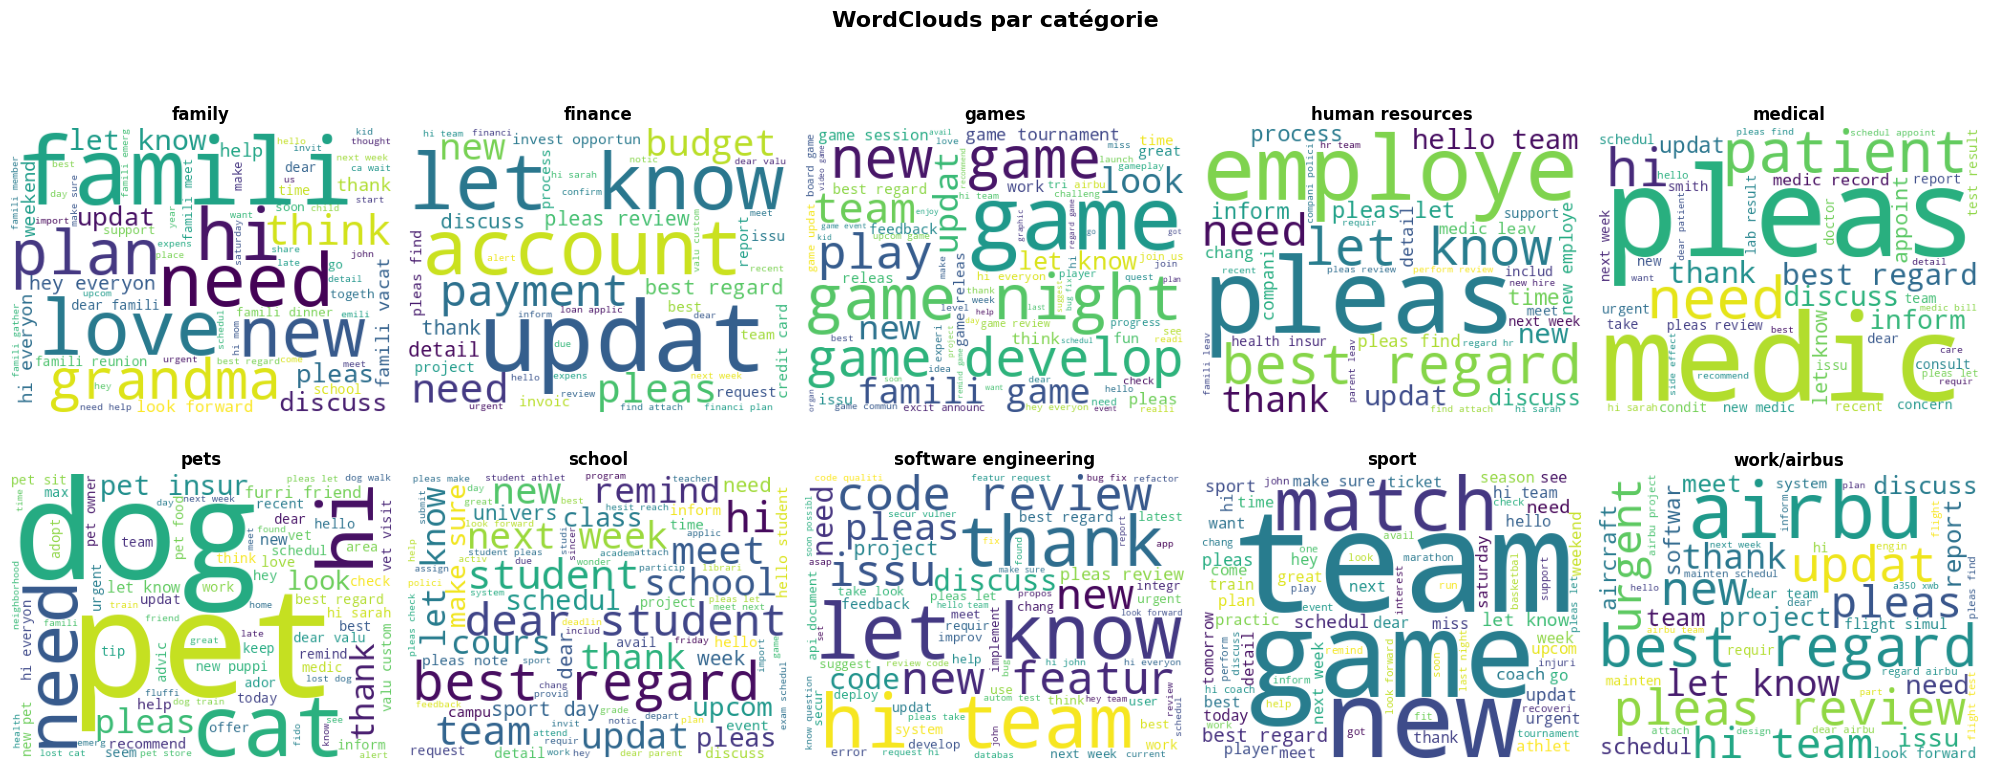

In [14]:
wc = WordCloud(width=400, height=300, min_font_size=8, background_color='white')

labels_sorted = sorted(df['label'].unique())
n = len(labels_sorted)
ncols = 5
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows * 4))
axes = axes.flatten()

for i, current_label in enumerate(labels_sorted):
    text_blob = df[df['label'] == current_label]['transformed_text'].str.cat(sep=' ')
    wc_img = wc.generate(text_blob)
    axes[i].imshow(wc_img)
    axes[i].set_title(f'{current_label}', fontsize=12, fontweight='bold')
    axes[i].axis('off')

# Masquer les axes vides si nombre impair
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle('WordClouds par catégorie', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>6.3 | WordCloud global</b></span>

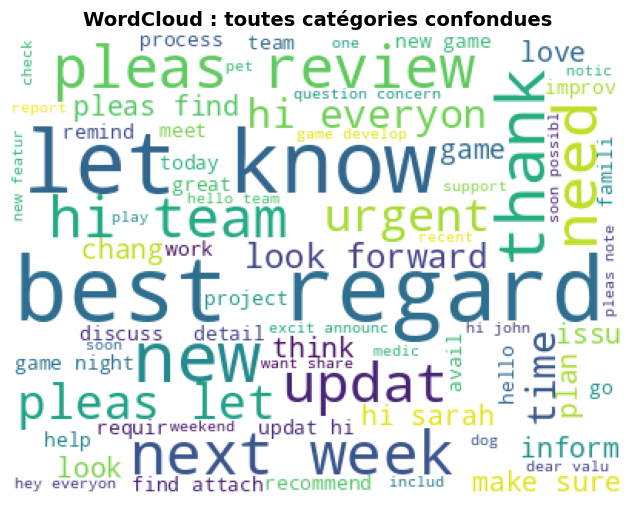

In [15]:
all_wc = wc.generate(df['transformed_text'].str.cat(sep=' '))
plt.figure(figsize=(15, 6))
plt.imshow(all_wc)
plt.title('WordCloud : toutes catégories confondues', fontsize=14, fontweight='bold')
plt.axis('off')
plt.show()

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>6.4 | Top 30 mots par catégorie (boucle)</b></span>

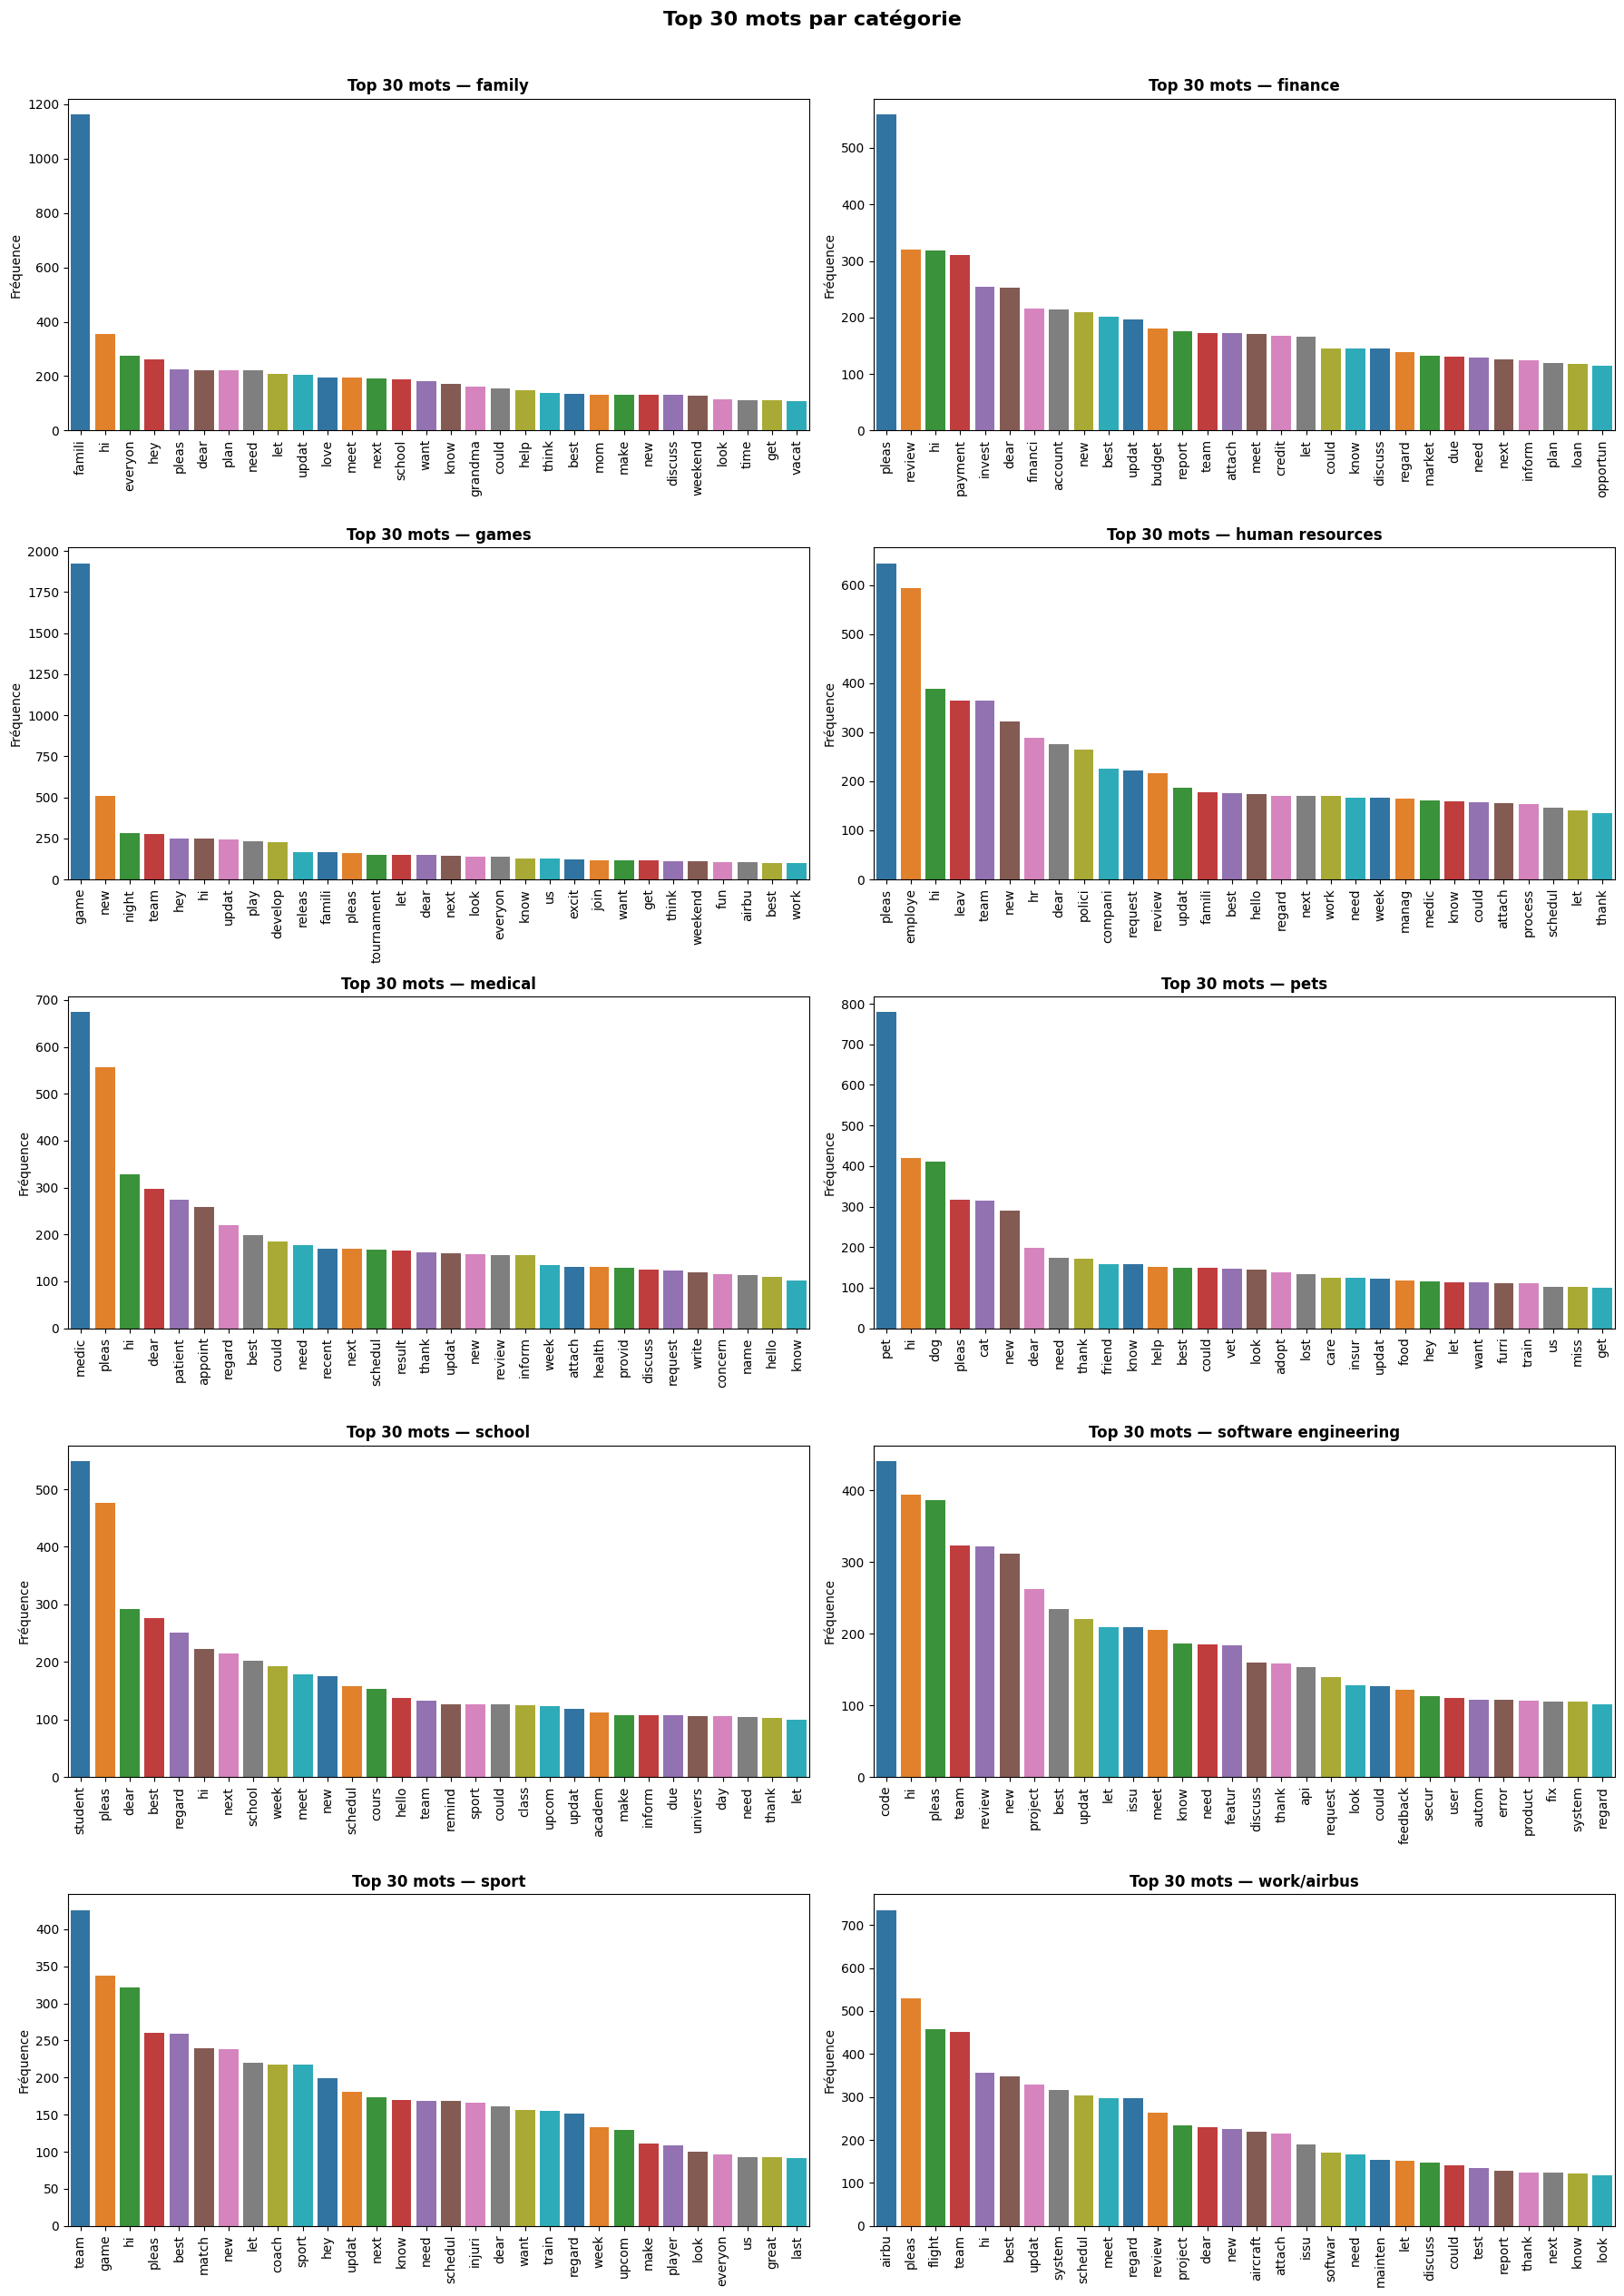

In [16]:
from collections import Counter

labels_sorted = sorted(df['label'].unique())
n = len(labels_sorted)
ncols = 2
nrows = (n + 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 5))
axes = axes.flatten()

for i, lbl in enumerate(labels_sorted):
    words = []
    for sentence in df[df['label'] == lbl]['transformed_text'].tolist():
        words.extend(sentence.split())
    freq_df = pd.DataFrame(Counter(words).most_common(30))
    sns.barplot(data=freq_df, x=0, y=1, hue=0, palette='tab10', legend=False, ax=axes[i])
    axes[i].set_title(f'Top 30 mots — {lbl}', fontsize=12, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=90)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Fréquence')

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle('Top 30 mots par catégorie', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

<div style="text-align: center; background: linear-gradient(to right, #FF00CC, #660066); font-family: 'Trebuchet MS', Arial, sans-serif; color: white; padding: 15px; font-size: 26px; font-weight: bold; line-height: 1; border-radius: 50% 0 50% 0 / 40px; margin-bottom: 20px; box-shadow: 0px 4px 6px rgba(0, 0, 0, 0.1);">7. Model Building (ML classique)</div>

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>7.1 | Vectorisation TF-IDF</b></span>

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfid = TfidfVectorizer(max_features=3000)
X = tfid.fit_transform(df['transformed_text']).toarray()
y = df['target'].values

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>7.2 | Train / Test split</b></span>

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=2, stratify=y
)

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>7.3 | Initialisation et entraînement des modèles</b></span>

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, BaggingClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score

clfs = {
    'SVC':      SVC(kernel='sigmoid', gamma=1.0),
    'KNN':      KNeighborsClassifier(),
    'NB':       MultinomialNB(),
    'DT':       DecisionTreeClassifier(max_depth=5),
    'LR':       LogisticRegression(solver='lbfgs', max_iter=2000),
    'RF':       RandomForestClassifier(n_estimators=50, random_state=2),
    'Adaboost': AdaBoostClassifier(n_estimators=50, random_state=2),
    'Bgc':      BaggingClassifier(n_estimators=50, random_state=2),
    'ETC':      ExtraTreesClassifier(n_estimators=50, random_state=2),
    'GBDT':     GradientBoostingClassifier(n_estimators=50, random_state=2),
    'xgb':      XGBClassifier(n_estimators=50, random_state=2)
}

In [20]:
# Tableau de bord global
performance_df = pd.DataFrame({
    'Méthode':   pd.Series(dtype='str'),
    'Accuracy':  pd.Series(dtype='float'),
    'Precision': pd.Series(dtype='float')
})

def update_performance(method_name, y_true, y_pred):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    new_row = pd.DataFrame({'Méthode': [method_name], 'Accuracy': [acc], 'Precision': [prec]})
    global performance_df
    performance_df = pd.concat([performance_df, new_row], ignore_index=True)
    print(f"✅ {method_name} — Accuracy: {acc:.4f} | Macro-Precision: {prec:.4f}")

for name, clf in clfs.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    update_performance(name, y_test, y_pred)

display(performance_df)

✅ SVC — Accuracy: 0.9168 | Macro-Precision: 0.9168
✅ KNN — Accuracy: 0.8580 | Macro-Precision: 0.8571
✅ NB — Accuracy: 0.8903 | Macro-Precision: 0.8899
✅ DT — Accuracy: 0.4308 | Macro-Precision: 0.6981
✅ LR — Accuracy: 0.9120 | Macro-Precision: 0.9117
✅ RF — Accuracy: 0.8786 | Macro-Precision: 0.8780
✅ Adaboost — Accuracy: 0.6073 | Macro-Precision: 0.8084
✅ Bgc — Accuracy: 0.8559 | Macro-Precision: 0.8569
✅ ETC — Accuracy: 0.9004 | Macro-Precision: 0.8996
✅ GBDT — Accuracy: 0.8649 | Macro-Precision: 0.8779
✅ xgb — Accuracy: 0.8945 | Macro-Precision: 0.8950


,Méthode,Accuracy,Precision
0,SVC,0.916799,0.916755
1,KNN,0.857976,0.857050
2,NB,0.890302,0.889893
3,DT,0.430843,0.698140
4,LR,0.912030,0.911693
5,RF,0.878643,0.878041
6,Adaboost,0.607313,0.808413
7,Bgc,0.855856,0.856855
8,ETC,0.900371,0.899555
9,GBDT,0.864865,0.877880


> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>8.1 | Tokenization Keras</b></span>

In [22]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

mon_tokenizer = Tokenizer(num_words=3000)
mon_tokenizer.fit_on_texts(df['transformed_text'])
sequences = mon_tokenizer.texts_to_sequences(df['transformed_text'])

# Longueur variable : on calcule le 95e percentile pour éviter le padding excessif
lengths = [len(s) for s in sequences]
max_len = int(np.percentile(lengths, 95))
print(f'Longueur max retenue (95e percentile) : {max_len}')

X_deep = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')

I0000 00:00:1778004851.087361    9177 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1778004851.975261    9177 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1778004853.197428    9177 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Longueur max retenue (95e percentile) : 29


> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>8.2 | Split des données</b></span>

In [23]:
X_train_deep, X_test_deep, y_train_dl, y_test_dl = train_test_split(
    X_deep, df['target'], test_size=0.2, random_state=2, stratify=df['target']
)

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>8.3 | Construction du modèle LSTM</b></span>

In [24]:
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout
from tensorflow.keras.models import Model

num_classes = len(encoder.classes_)

input_text = Input(shape=(max_len,), name='Entree_Texte')
x = Embedding(input_dim=3000, output_dim=64)(input_text)
x = LSTM(64, return_sequences=True)(x)
x = LSTM(32)(x)
x = Dropout(0.3)(x)
x = Dense(64, activation='relu')(x)
output = Dense(num_classes, activation='softmax')(x)

model_complet = Model(inputs=input_text, outputs=output)
model_complet.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model_complet.summary()

E0000 00:00:1778004866.144206    9177 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
I0000 00:00:1778004866.144240    9177 cuda_diagnostics.cc:171] verbose logging is disabled. Rerun with verbose logging (usually --v=1 or --vmodule=cuda_diagnostics=1) to get more diagnostic output from this module
I0000 00:00:1778004866.144242    9177 cuda_diagnostics.cc:176] retrieving CUDA diagnostic information for host: localhost.localdomain
I0000 00:00:1778004866.144244    9177 cuda_diagnostics.cc:183] hostname: localhost.localdomain
I0000 00:00:1778004866.144277    9177 cuda_diagnostics.cc:190] libcuda reported version is: NOT_FOUND: was unable to find libcuda.so DSO loaded into this program. The library may be missing or provided via another object.
I0000 00:00:1778004866.144290    9177 cuda_diagnostics.cc:194] kernel reported version is: 595.45.4


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Entree_Texte (InputLayer)       │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 29, 64)         │       192,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 29, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 240,202 (938.29 KB)

 Trainable params: 240,202 (938.29 KB)

 Non-trainable params: 0 (0.00 B)

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>8.4 | Entraînement</b></span>

In [25]:
history = model_complet.fit(
    x=X_train_deep,
    y=y_train_dl,
    epochs=15,
    batch_size=32,
    validation_data=(X_test_deep, y_test_dl)
)

Epoch 1/15
236/236 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.3158 - loss: 1.7794 - val_accuracy: 0.5665 - val_loss: 1.1560
Epoch 2/15
236/236 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6443 - loss: 0.9760 - val_accuracy: 0.7382 - val_loss: 0.8078
Epoch 3/15
236/236 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7959 - loss: 0.6510 - val_accuracy: 0.8082 - val_loss: 0.6338
Epoch 4/15
236/236 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8864 - loss: 0.4361 - val_accuracy: 0.8691 - val_loss: 0.4743
Epoch 5/15
236/236 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9115 - loss: 0.3462 - val_accuracy: 0.8686 - val_loss: 0.4921
Epoch 6/15
236/236 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9332 - loss: 0.2732 - val_accuracy: 0.8818 - val_loss: 0.4760
Epoch 7/15
236/236 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9463 - loss: 0.2232 - val_accuracy: 0.8670 - val_loss: 0.5603
Epoch 8/15
236/236 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9608 - loss: 0.1714 - val_accuracy: 0.

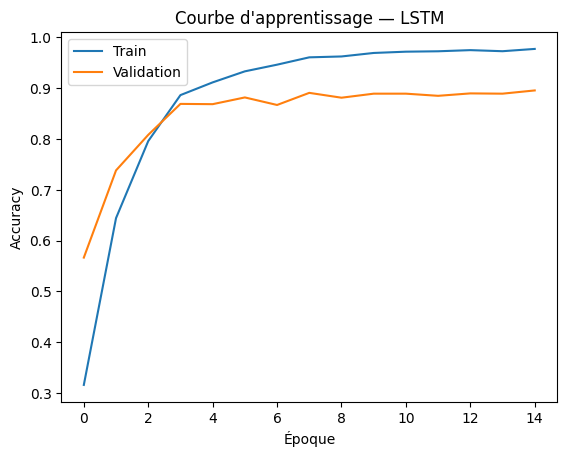

In [26]:
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Courbe d\'apprentissage — LSTM')
plt.ylabel('Accuracy')
plt.xlabel('Époque')
plt.legend()
plt.show()

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>8.5 | Évaluation LSTM</b></span>

59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
✅ LSTM (DL) — Accuracy: 0.8956 | Macro-Precision: 0.8968


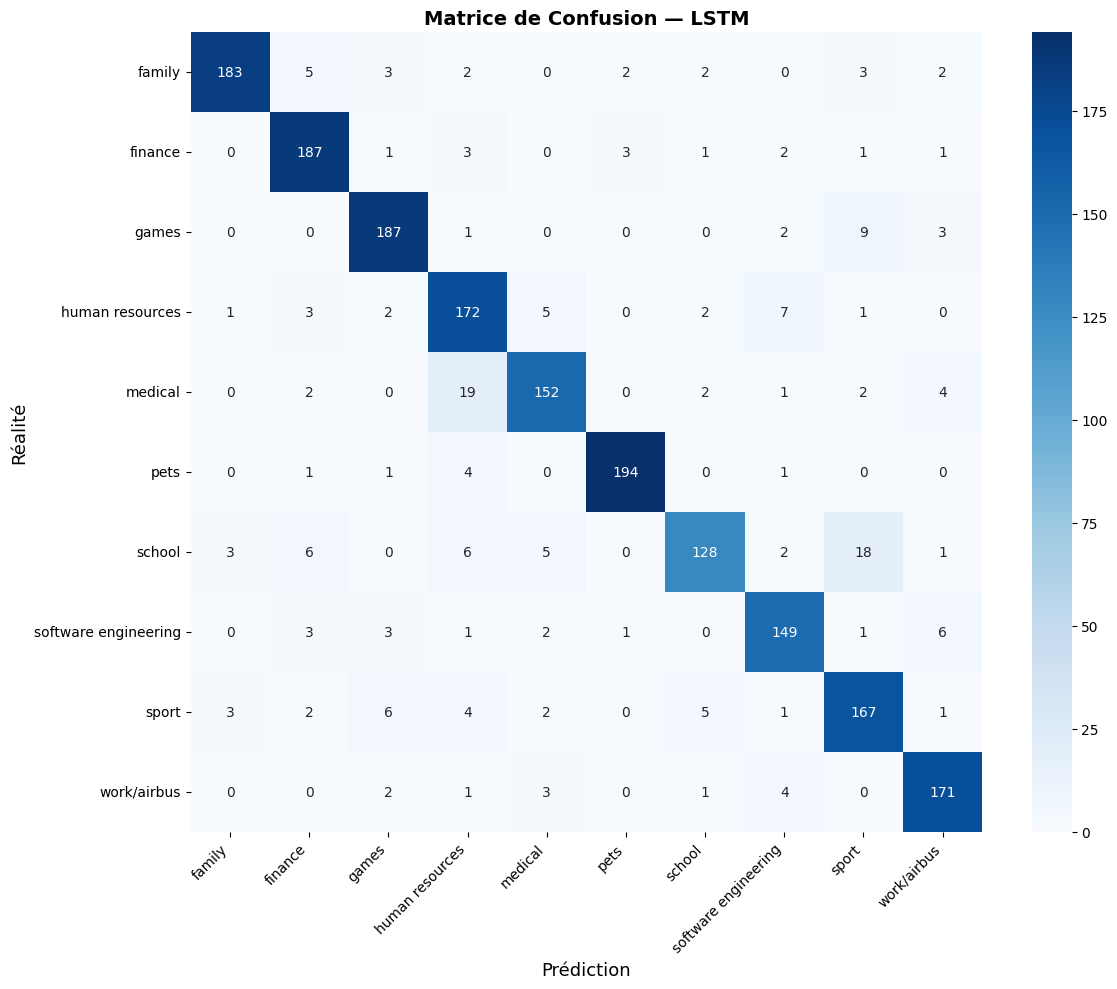

                      precision    recall  f1-score   support

              family       0.96      0.91      0.93       202
             finance       0.89      0.94      0.92       199
               games       0.91      0.93      0.92       202
     human resources       0.81      0.89      0.85       193
             medical       0.90      0.84      0.87       182
                pets       0.97      0.97      0.97       201
              school       0.91      0.76      0.83       169
software engineering       0.88      0.90      0.89       166
               sport       0.83      0.87      0.85       191
         work/airbus       0.90      0.94      0.92       182

            accuracy                           0.90      1887
           macro avg       0.90      0.89      0.89      1887
        weighted avg       0.90      0.90      0.90      1887



In [27]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

y_pred_proba_1 = model_complet.predict(X_test_deep)
y_pred_1 = np.argmax(y_pred_proba_1, axis=1)

update_performance('LSTM (DL)', y_test_dl, y_pred_1)

cm = confusion_matrix(y_test_dl, y_pred_1)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=encoder.classes_, yticklabels=encoder.classes_)
plt.xlabel('Prédiction', fontsize=13)
plt.ylabel('Réalité', fontsize=13)
plt.title('Matrice de Confusion — LSTM', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(classification_report(y_test_dl, y_pred_1, target_names=list(encoder.classes_), zero_division=0))

<div style="text-align: center; background: #FF00CC; font-family: 'Trebuchet MS', Arial, sans-serif; color: white; padding: 15px; font-size: 26px; font-weight: bold; line-height: 1; border-radius: 50% 0 50% 0 / 40px; margin-bottom: 20px; box-shadow: 0px 4px 6px rgba(0, 0, 0, 0.1);">9. Fine-tuning — DistilBERT</div>

## 📊 Comparaison des modèles BERT

| Modèle | Paramètres | Taille | Vitesse | Performance | Cas d'usage |
|--------|-----------|--------|---------|------------|-----------|
| **BERT** (original) | 110M | 440 MB | 🐢 Lent | ⭐⭐⭐⭐⭐ | Production |
| **DistilBERT** (actuellement) | 66M | 268 MB | 🚗 Moyen | ⭐⭐⭐⭐⭐ | **Bon compromis** ✅ |
| **TinyBERT** | 14M | 56 MB | ⚡⚡ Extrêmement rapide | ⭐⭐⭐ | Très léger |
| **ALBERT-small** | 12M | 48 MB | ⚡⚡ Extrêmement rapide | ⭐⭐⭐ | Très compact |

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>9.1 | Chargement du modèle pré-entraîné</b></span>

In [28]:
from transformers import AutoTokenizer, AutoModel
import torch

def load_model(model_choice):
    models_dict = {
        'bert':       'bert-base-uncased',
        'distilbert': 'distilbert-base-uncased',
        'albert':     'albert-base-v2',
        'tinybert':   'huawei-noah/TinyBERT_General_6L_768D'
    }
    model_name = models_dict.get(model_choice)
    if not model_name:
        print(f"❌ Modèle '{model_choice}' non trouvé!")
        return None, None

    print(f"🔄 Chargement de {model_choice}...")
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name)

    for param in model.parameters():
        param.requires_grad = False
    model.eval()

    return tokenizer, model

model_choice = 'distilbert'
tokenizer, bert_model = load_model(model_choice)
print(f"✅ {model_choice} chargé avec succès !")

🔄 Chargement de distilbert...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ distilbert chargé avec succès !


> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>9.2 | Tokenization BERT (longueur variable)</b></span>

In [29]:
print("🔄 Tokenization des emails...")

# Longueur variable : 95e percentile plafonné à 512 (limite BERT)
bert_lengths = [len(tokenizer.encode(t, truncation=False)) for t in df['text']]
bert_max_len = min(int(np.percentile(bert_lengths, 95)), 512)
print(f'Longueur max BERT retenue : {bert_max_len}')

X_bert = np.array([
    tokenizer.encode(text, max_length=bert_max_len, padding='max_length', truncation=True)
    for text in df['text']
])
y = df['target'].values

print(f"✅ X_bert shape: {X_bert.shape}")

🔄 Tokenization des emails...
Longueur max BERT retenue : 64
✅ X_bert shape: (9432, 64)


> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>9.3 | Split des données BERT</b></span>

In [30]:
train_ids, test_ids, y_train_bert, y_test_bert = train_test_split(
    X_bert, y, test_size=0.2, random_state=2, stratify=y
)
print(f"✅ Train: {train_ids.shape} | Test: {test_ids.shape}")

✅ Train: (7545, 64) | Test: (1887, 64)


> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>9.4 | Pré-calcul des embeddings CLS</b></span>

In [31]:
print("⏳ Pré-calcul des features BERT (peut prendre quelques minutes)...\n")

BATCH = 64  # Traiter par batch pour éviter les OOM

def extract_cls(ids_array, model, batch_size=64):
    all_cls = []
    for i in range(0, len(ids_array), batch_size):
        batch = torch.tensor(ids_array[i:i+batch_size])
        with torch.no_grad():
            out = model(batch)
        all_cls.append(out[0][:, 0, :].numpy())
    return np.vstack(all_cls)

train_cls = extract_cls(train_ids, bert_model, BATCH)
test_cls  = extract_cls(test_ids, bert_model, BATCH)

print(f"✅ train_cls: {train_cls.shape}")
print(f"✅ test_cls:  {test_cls.shape}")

⏳ Pré-calcul des features BERT (peut prendre quelques minutes)...

✅ train_cls: (7545, 768)
✅ test_cls:  (1887, 768)


> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>9.5 | Construction du modèle BERT + tête de classification</b></span>

In [32]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.models import Model

num_classes = len(encoder.classes_)

input_bert = Input(shape=(768,), name='bert_features')
x = Dense(128, activation='relu')(input_bert)
x = Dropout(0.3)(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.2)(x)
output = Dense(num_classes, activation='softmax')(x)

model_bert = Model(inputs=input_bert, outputs=output)
model_bert.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print(f"✅ Modèle BERT créé — {model_bert.count_params():,} paramètres")

✅ Modèle BERT créé — 107,338 paramètres


> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>9.6 | Entraînement de la tête de classification</b></span>

In [33]:
print("🚀 Entraînement...\n")

history_bert = model_bert.fit(
    x=train_cls,
    y=y_train_bert,
    epochs=10,
    batch_size=32,
    validation_data=(test_cls, y_test_bert),
    verbose=1
)

print("\n✅ Entraînement terminé !")

🚀 Entraînement...

Epoch 1/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5254 - loss: 1.3891 - val_accuracy: 0.7912 - val_loss: 0.6646
Epoch 2/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7677 - loss: 0.7038 - val_accuracy: 0.8744 - val_loss: 0.4341
Epoch 3/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8170 - loss: 0.5690 - val_accuracy: 0.8755 - val_loss: 0.4193
Epoch 4/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8339 - loss: 0.5088 - val_accuracy: 0.8670 - val_loss: 0.4023
Epoch 5/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8447 - loss: 0.4806 - val_accuracy: 0.8914 - val_loss: 0.3480
Epoch 6/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8611 - loss: 0.4412 - val_accuracy: 0.8972 - val_loss: 0.3390
Epoch 7/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8627 - loss: 0.4247 - val_accuracy: 0.8956 - val_loss: 0.3372
Epoch 8/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8679 - loss: 0.3992

> <span style='font-size:15px; font-family:Verdana;color: #FF00CC;'><b>9.7 | Évaluation BERT</b></span>

59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 834us/step
✅ DistilBERT — Accuracy: 0.8951 | Macro-Precision: 0.8987


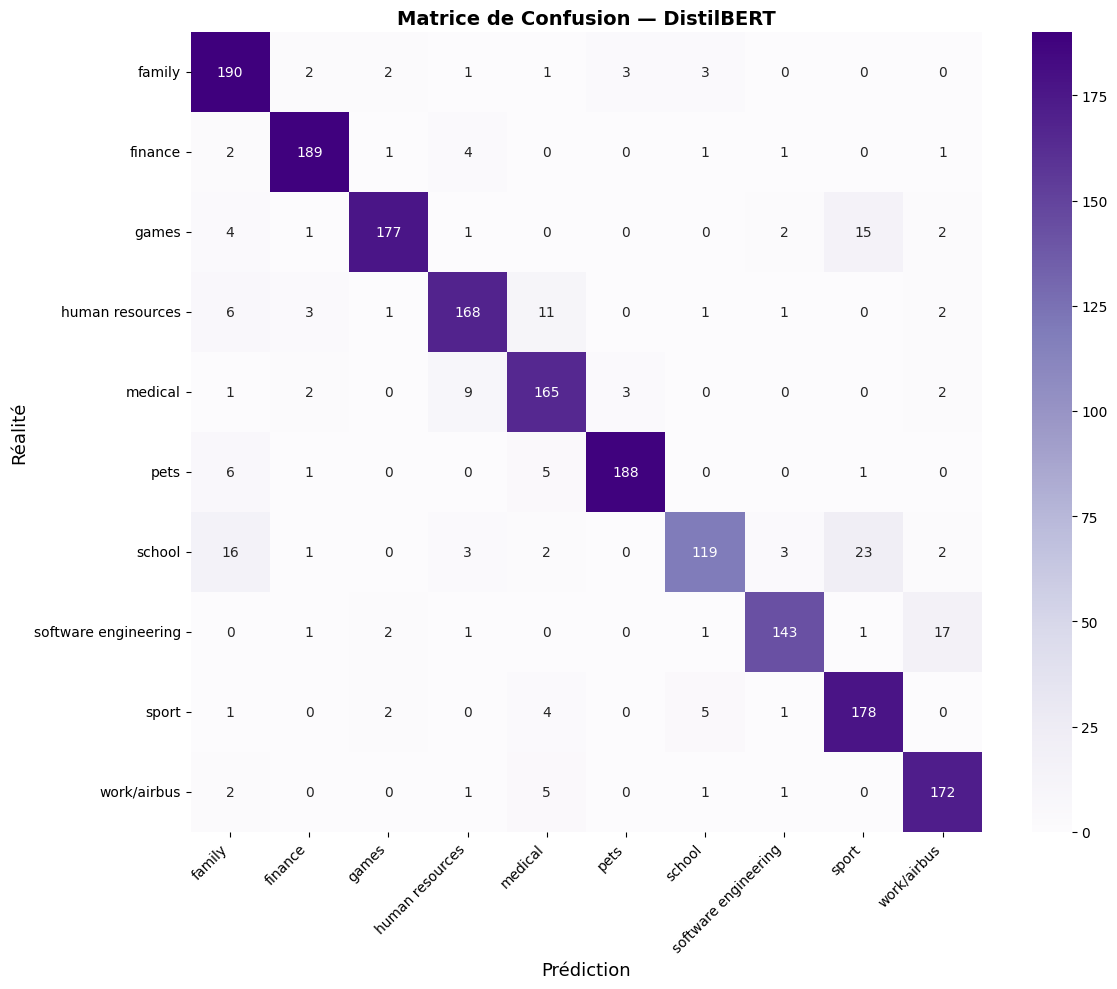

                      precision    recall  f1-score   support

              family       0.83      0.94      0.88       202
             finance       0.94      0.95      0.95       199
               games       0.96      0.88      0.91       202
     human resources       0.89      0.87      0.88       193
             medical       0.85      0.91      0.88       182
                pets       0.97      0.94      0.95       201
              school       0.91      0.70      0.79       169
software engineering       0.94      0.86      0.90       166
               sport       0.82      0.93      0.87       191
         work/airbus       0.87      0.95      0.91       182

            accuracy                           0.90      1887
           macro avg       0.90      0.89      0.89      1887
        weighted avg       0.90      0.90      0.89      1887



In [34]:
y_pred_proba = model_bert.predict(test_cls)
y_pred_bert  = np.argmax(y_pred_proba, axis=1)

update_performance('DistilBERT', y_test_bert, y_pred_bert)

cm = confusion_matrix(y_test_bert, y_pred_bert)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=encoder.classes_, yticklabels=encoder.classes_)
plt.xlabel('Prédiction', fontsize=13)
plt.ylabel('Réalité', fontsize=13)
plt.title('Matrice de Confusion — DistilBERT', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(classification_report(y_test_bert, y_pred_bert, target_names=list(encoder.classes_), zero_division=0))

<div style="text-align: center; background: #FF00CC; font-family: 'Trebuchet MS', Arial, sans-serif; color: white; padding: 15px; font-size: 26px; font-weight: bold; line-height: 1; border-radius: 50% 0 50% 0 / 40px; margin-bottom: 20px; box-shadow: 0px 4px 6px rgba(0, 0, 0, 0.1);">10. Comparaison finale des modèles</div>

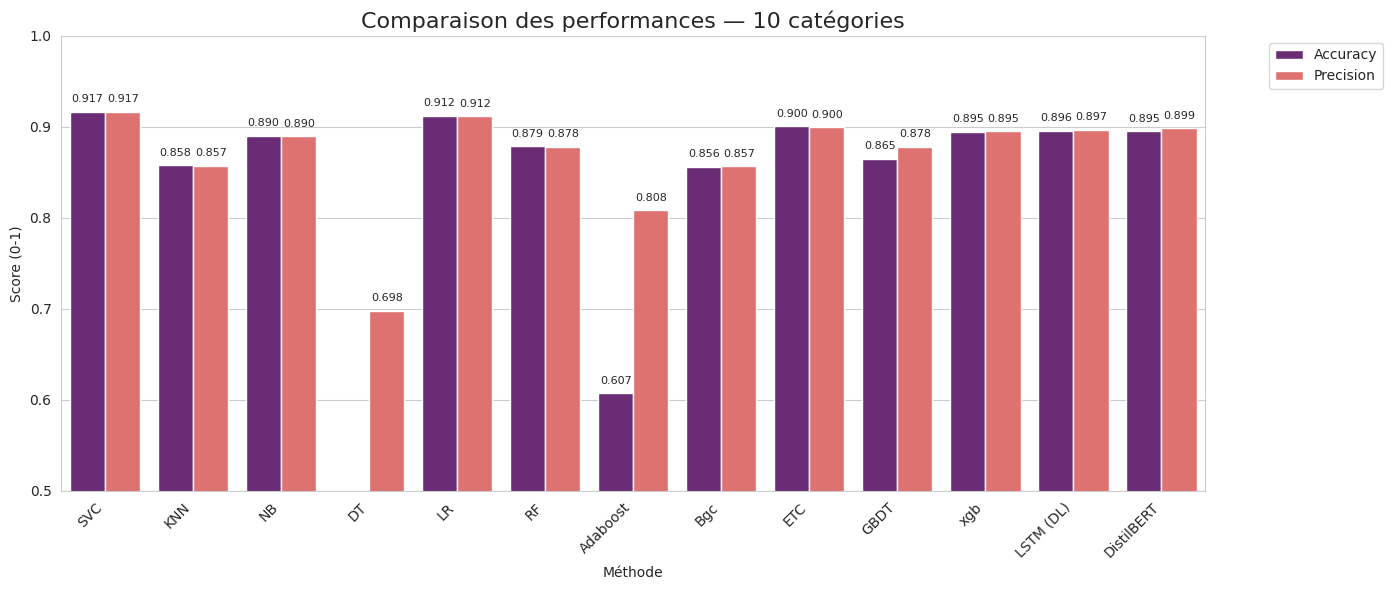

,Méthode,Accuracy,Precision
0,SVC,0.916799,0.916755
1,LR,0.912030,0.911693
2,ETC,0.900371,0.899555
3,LSTM (DL),0.895601,0.896796
4,DistilBERT,0.895072,0.898709
5,xgb,0.894542,0.895007
6,NB,0.890302,0.889893
7,RF,0.878643,0.878041
8,GBDT,0.864865,0.877880
9,KNN,0.857976,0.857050


In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

df_melted = performance_df.melt(id_vars='Méthode', var_name='Métrique', value_name='Score')

plt.figure(figsize=(14, 6))
sns.set_style('whitegrid')

ax = sns.barplot(data=df_melted, x='Méthode', y='Score', hue='Métrique', palette='magma')

plt.title('Comparaison des performances — 10 catégories', fontsize=16)
plt.ylim(0.5, 1.0)  # Adapté à 10 classes (scores potentiellement plus bas)
plt.ylabel('Score (0-1)')
plt.xticks(rotation=45, ha='right')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.3f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center',
                    xytext=(0, 9), textcoords='offset points', fontsize=8)

plt.tight_layout()
plt.show()

display(performance_df.sort_values('Accuracy', ascending=False).reset_index(drop=True))

<div style="background-color:white;font-size:15px;font-family:Georgia;border-style: solid;border-color: #FF00CC;border-width:3px;padding:10px;margin: 1px;color:#254E58;overflow:hidden"> 

<h4><b style = 'color: red;'>Améliorations possibles :

<b>👉 Cross-validation KFold pour stabiliser les scores sur 10 classes <br>
<b>👉 Tester CamemBERT ou FlauBERT si les emails sont en français <br>
<b>👉 Data augmentation (synonymes, suppression aléatoire de mots) pour les classes sous-représentées <br>
<b>👉 Ajuster le class_weight dans sklearn pour équilibrer les classes déséquilibrées <br>
<b>👉 Mesure du temps d'inférence et des ressources GPU/CPU <br>
<b>👉 En multiclasse, la décision finale se fait via argmax (pas de seuil à ajuster) <br>